# Modelos: riesgo de adición en contratos de obra pública (SECOP II)

**Pregunta de negocio.** ¿Qué contratos de obra pública firmados en SECOP II
tienen mayor probabilidad de recibir adiciones en tiempo o en valor durante su
ejecución, usando solo información disponible al momento de la firma, para que
la DIARI y las veedurías prioricen su seguimiento preventivo?

**Tarea.** Clasificación binaria supervisada. `y = 1` si el contrato registra
adición en tiempo (`dias_adicionados > 0`) o en valor (tabla Adiciones, tipo
"Adicion en el valor"). `y_tiempo` e `y_valor` son sus dos componentes.

**Procedimiento.**

1. Tabla de modelado: `src/features.py`, con las reglas del EDA
   (`notebooks/01_eda_obra.ipynb`, sección 17).
2. Modelos, validación y métricas: `src/modelo.py`.
3. Se comparan cuatro modelos (regresión logística, Random Forest, LightGBM y
   CatBoost) con el mismo preprocesamiento.
4. Selección del modelo y de las variables con validación temporal de
   ventana creciente (2022, 2023 y 2024) y prueba única en 2025.
5. Los experimentos se registran en MLflow con las mismas funciones
   (`validar`, `buscar`, `entrenar`); las cifras de este notebook coinciden
   con las corridas registradas porque las semillas son fijas.

## 1. Configuración

In [1]:
import contextlib
import io
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve

sys.path.insert(0, "../src")
from features import (CATEGORICAS, NUMERICAS, OBJETIVOS,  # noqa: E402
                      VARIABLES, cargar)
from modelo import (GANADOR, MODELOS, PLIEGUES, PRUEBA,  # noqa: E402
                    SEMILLA, aportes, buscar, calibrar, entrenar,
                    pipeline, recalibrar, validar)

warnings.filterwarnings("ignore", message="X does not have valid feature")
FIG = Path("../reports/figures")
NOMBRES = {"logistica": "Regresión logística",
           "random_forest": "Random Forest", "lightgbm": "LightGBM",
           "catboost": "CatBoost"}
PRINCIPALES = ["pr_auc", "roc_auc", "precision_100", "precision_10pct",
               "recall_10pct", "lift_10pct", "brier"]
ETIQUETAS = {
    "log_valor_inicial": "Valor inicial (log)",
    "plazo_inicial": "Plazo inicial", "respuestas": "Respuestas al proceso",
    "inicial_sobre_base": "Valor inicial / precio base",
    "dias_publicacion_adjudicacion": "Días publicación a adjudicación",
    "tasa_entidad": "Tasa histórica de la entidad",
    "previos_entidad": "Contratos previos de la entidad",
    "antiguedad_prov": "Antigüedad del proveedor",
    "proceso_compartido": "Proceso compartido (lotes)",
    "proveedor_repetido": "Proveedor repetido con la entidad",
    "nombre_entidad": "Entidad", "modalidad": "Modalidad",
    "departamento": "Departamento", "segmento_unspsc": "Segmento UNSPSC",
    "fuente_principal": "Fuente principal de recursos",
    "destino_gasto": "Destino del gasto",
    "condiciones_de_entrega": "Condiciones de entrega", "es_pyme": "Pyme",
    "tipodocproveedor": "Tipo de documento del proveedor",
    "mes": "Mes de firma",
}
FINAL = dict(params=GANADOR["params"], excluir=GANADOR["excluir"])
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format


def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150)
    plt.show()


def resumir(metricas):
    """Media y desviación entre pliegues de las métricas principales."""
    m = metricas[PRINCIPALES]
    return (m.mean().map("{:.3f}".format) + " ± "
            + m.std().map("{:.3f}".format))

## 2. Datos y partición

1. Se carga la tabla de modelado: contratos de obra firmados entre 2019 y
   2025, sin los que tienen el plazo inicial vigente a la fecha de descarga.
2. Se describen las tasas de cada objetivo por año.
3. La partición es temporal: cada pliegue entrena con los años anteriores al
   año evaluado. 2025 se reserva como prueba y no se usa para elegir.

In [2]:
datos = cargar()
print(f"Contratos: {len(datos):,}")
print(datos.groupby("anio").agg(
    contratos=("y", "size"), y=("y", "mean"), y_tiempo=("y_tiempo", "mean"),
    y_valor=("y_valor", "mean")).to_string())

anios = PLIEGUES + [PRUEBA]
print()
print(pd.DataFrame({
    "entrena": [f"2019-{a - 1}" for a in anios],
    "contratos de entrenamiento": [(datos["anio"] < a).sum() for a in anios],
    "evalúa": anios,
    "contratos evaluados": [(datos["anio"] == a).sum() for a in anios],
    "uso": ["validación"] * len(PLIEGUES) + ["prueba"],
}).to_string(index=False))

Contratos: 40,170
      contratos     y  y_tiempo  y_valor
anio                                    
2019       2291 0.353     0.135    0.242
2020       2757 0.346     0.201    0.176
2021       5393 0.347     0.261    0.111
2022       5954 0.338     0.252    0.106
2023       7944 0.297     0.227    0.089
2024       6468 0.349     0.280    0.087
2025       9363 0.470     0.425    0.079

  entrena  contratos de entrenamiento  evalúa  contratos evaluados        uso
2019-2021                       10441    2022                 5954 validación
2019-2022                       16395    2023                 7944 validación
2019-2023                       24339    2024                 6468 validación
2019-2024                       30807    2025                 9363     prueba


**Hallazgos.**

1. La tabla tiene 40.170 contratos. La tasa de `y` está entre 29,7 % y 35,3 %
   de 2019 a 2024 y sube a 47,0 % en 2025.
2. Sus componentes se mueven en sentidos opuestos: `y_tiempo` pasa de 13,5 %
   en 2019 a 42,5 % en 2025 y `y_valor` baja de 24,2 % a 7,9 %. Es el cambio
   en la práctica de registro descrito en el EDA.
3. Cada pliegue entrena con al menos 10.441 contratos; la prueba tiene 9.363.

## 3. Variables y preprocesamiento

1. Se parte de 19 variables candidatas conocidas al firmar, seleccionadas en
   el EDA por su señal univariada (AUC), su cobertura y la ausencia de fuga.
   La sección 7 depura esta lista con el modelo seleccionado.
2. Se excluyen por fuga: estado, valor y duración actuales, fecha de fin,
   días adicionados, días entre firma e inicio, montos por fuente y variables
   de ejecución. Se excluyen por redundancia o falta de señal: proponentes,
   contratos previos del proveedor, orden, origen de los recursos, pago
   adelantado y justificación de la modalidad.
3. Preprocesamiento común a los cuatro modelos:
   1. Numéricas: imputación por mediana, indicador de faltante y escala.
   2. Entidad (2.370 entidades): en lugar del nombre se usa la tasa de
      adición de la entidad calculada solo con los años anteriores al de la
      firma y suavizada hacia la tasa global con un peso de 20 contratos
      (`tasa_entidad`). Así ningún contrato de entrenamiento se codifica con
      desenlaces posteriores de su entidad (auditoría 05).
   3. Categóricas: one-hot; las categorías con menos de 50 contratos se
      agrupan y las desconocidas se tratan como infrecuentes.

In [3]:
tratamiento = pd.Series(
    {**{v: "numérica" for v in NUMERICAS},
     **{v: "one-hot" for v in CATEGORICAS}})
categorias = datos[VARIABLES].nunique().where(tratamiento != "numérica")
print(pd.DataFrame({
    "tratamiento": tratamiento,
    "% faltante": datos[VARIABLES].isna().mean() * 100,
    "categorías": categorias,
}).round(1).to_string())

entrena = datos[datos["anio"] < PRUEBA]
prep = pipeline(GANADOR["modelo"])["prep"].fit(entrena[VARIABLES],
                                               entrena["y"])
print(f"\nColumnas tras el preprocesamiento: "
      f"{len(prep.get_feature_names_out())}")

                              tratamiento  % faltante  categorías
log_valor_inicial                numérica       0.100         NaN
plazo_inicial                    numérica       9.700         NaN
respuestas                       numérica       0.000         NaN
inicial_sobre_base               numérica      26.700         NaN
dias_publicacion_adjudicacion    numérica      29.600         NaN
tasa_entidad                     numérica       5.700         NaN
previos_entidad                  numérica       0.000         NaN
antiguedad_prov                  numérica      32.800         NaN
proceso_compartido               numérica       0.000         NaN
proveedor_repetido               numérica       0.000         NaN
modalidad                         one-hot       0.000       5.000
departamento                      one-hot       2.400      33.000
segmento_unspsc                   one-hot      16.100      54.000
fuente_principal                  one-hot       8.200       6.000
destino_ga


Columnas tras el preprocesamiento: 109


**Hallazgos.**

1. Cuatro numéricas tienen faltantes relevantes: antigüedad del proveedor
   (32,8 %), días de publicación a adjudicación (29,6 %), valor inicial /
   precio base (26,7 %) y plazo inicial (9,7 %). Cada una recibe un indicador
   de faltante.
2. La tasa histórica de la entidad falta solo en los contratos de 2019
   (5,7 %), que no tienen años previos.
3. Entre las categóricas, condiciones de entrega (36,0 %) y segmento UNSPSC
   (16,1 %) tienen más faltantes; el faltante se trata como una categoría.
4. Con las 19 variables candidatas, el preprocesamiento produce 109 columnas.

## 4. Modelos base

1. Se entrenan los cuatro modelos con hiperparámetros iniciales razonables.
2. Se reporta la media y la desviación entre los tres pliegues temporales.

In [4]:
base = pd.DataFrame({NOMBRES[m]: resumir(validar(m, datos=datos))
                     for m in MODELOS}).T
print(base.to_string())

                            pr_auc        roc_auc  precision_100 precision_10pct   recall_10pct     lift_10pct          brier
Regresión logística  0.505 ± 0.063  0.689 ± 0.038  0.593 ± 0.163   0.607 ± 0.048  0.185 ± 0.015  1.854 ± 0.152  0.202 ± 0.011
Random Forest        0.521 ± 0.061  0.700 ± 0.038  0.680 ± 0.192   0.612 ± 0.058  0.187 ± 0.020  1.871 ± 0.197  0.199 ± 0.009
LightGBM             0.510 ± 0.041  0.698 ± 0.031  0.660 ± 0.035   0.584 ± 0.041  0.179 ± 0.019  1.789 ± 0.190  0.202 ± 0.013
CatBoost             0.522 ± 0.045  0.707 ± 0.031  0.690 ± 0.096   0.605 ± 0.038  0.185 ± 0.015  1.848 ± 0.151  0.198 ± 0.010


**Hallazgos.**

1. Los cuatro modelos superan la tasa base media de validación (0,328), con
   PR-AUC entre 0,505 y 0,522 y AUC-ROC entre 0,689 y 0,707.
2. La variación entre años (desviación de 0,041 a 0,063) es mayor que la
   diferencia entre modelos (0,017).

## 5. Ajuste de hiperparámetros

1. Búsqueda corta en rejilla (`REJILLAS` en `src/modelo.py`), 22
   configuraciones en total.
2. Cada configuración se evalúa en los tres pliegues temporales y se ordena
   por PR-AUC medio.

In [5]:
resultados, mejores = [], {}
for m in MODELOS:
    r = buscar(m, datos=datos)
    mejores[m] = r.iloc[0]["params"]
    resultados.append(r.assign(modelo=NOMBRES[m]))
busqueda = pd.concat(resultados)
busqueda["configuración"] = busqueda["params"].map(
    lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))
print(busqueda[["modelo", "configuración", "pr_auc", "pr_auc_std",
                "roc_auc", "precision_100", "precision_10pct"]]
      .to_string(index=False))

             modelo                          configuración  pr_auc  pr_auc_std  roc_auc  precision_100  precision_10pct
Regresión logística                                 C=0.01   0.514       0.063    0.695          0.627            0.616
Regresión logística                                  C=0.1   0.508       0.062    0.691          0.607            0.610
Regresión logística                                    C=1   0.505       0.063    0.689          0.593            0.607
Regresión logística                                   C=10   0.504       0.063    0.688          0.597            0.606
      Random Forest  max_features=sqrt, min_samples_leaf=5   0.526       0.057    0.702          0.777            0.613
      Random Forest max_features=sqrt, min_samples_leaf=20   0.521       0.061    0.700          0.680            0.612
      Random Forest   max_features=0.3, min_samples_leaf=5   0.519       0.050    0.701          0.753            0.605
      Random Forest  max_features=0.3, m

**Hallazgos.**

1. La tasa de aprendizaje baja (0,03) es la mejor para LightGBM y CatBoost;
   con 0,1 ambos pierden entre 0,013 y 0,027 de PR-AUC por sobreajuste.
2. La regularización fuerte (C = 0,01) es la mejor opción para la logística
   (0,514 frente a 0,504 con C = 10).
3. En Random Forest gana la configuración con hojas de al menos 5 contratos y
   `max_features` sqrt (0,526).
4. El ajuste mejora entre 0,005 y 0,010 sobre los valores base: el desempeño
   depende más de la información disponible al firmar que de los
   hiperparámetros.

## 6. Comparación y selección

1. Se compara la mejor configuración de cada modelo pliegue a pliegue.
2. Regla de selección: mayor PR-AUC medio en los tres pliegues, sin
   criterio de desempate.
3. Como evidencia de la magnitud de las diferencias se reporta la diferencia
   pareada de cada modelo frente al seleccionado en cada año.
4. La selección se confirma con las corridas registradas en MLflow.

PR-AUC por pliegue:
        Regresión logística  Random Forest  LightGBM  CatBoost
evalua                                                        
2022                  0.469          0.493     0.492     0.500
2023                  0.486          0.494     0.509     0.508
2024                  0.586          0.591     0.558     0.576

                            pr_auc        roc_auc  precision_100 precision_10pct   recall_10pct     lift_10pct          brier
Regresión logística  0.514 ± 0.063  0.695 ± 0.042  0.627 ± 0.165   0.616 ± 0.050  0.188 ± 0.018  1.883 ± 0.176  0.200 ± 0.012
Random Forest        0.526 ± 0.057  0.702 ± 0.036  0.777 ± 0.081   0.613 ± 0.052  0.187 ± 0.017  1.873 ± 0.168  0.198 ± 0.008
LightGBM             0.520 ± 0.034  0.707 ± 0.031  0.673 ± 0.085   0.600 ± 0.036  0.184 ± 0.022  1.838 ± 0.219  0.198 ± 0.011
CatBoost             0.528 ± 0.042  0.711 ± 0.031  0.747 ± 0.051   0.610 ± 0.033  0.186 ± 0.015  1.865 ± 0.152  0.196 ± 0.010

Seleccionado: CatBoost {'depth': 

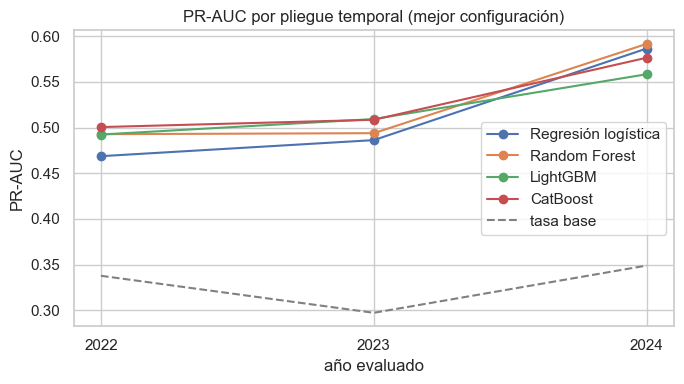

In [6]:
pliegues = {m: validar(m, params=mejores[m], datos=datos) for m in MODELOS}
pr = pd.DataFrame({m: r["pr_auc"] for m, r in pliegues.items()})
print("PR-AUC por pliegue:")
print(pr.rename(columns=NOMBRES).to_string())
print()
print(pd.DataFrame({NOMBRES[m]: resumir(r)
                    for m, r in pliegues.items()}).T.to_string())

seleccion = pr.mean().idxmax()
coincide = (seleccion == GANADOR["modelo"]
            and mejores[seleccion] == GANADOR["params"])
print(f"\nSeleccionado: {NOMBRES[seleccion]} {mejores[seleccion]}, "
      f"PR-AUC medio {pr[seleccion].mean():.3f}. "
      f"Coincide con GANADOR: {coincide}")
print(f"\nDiferencia pareada de PR-AUC frente a {NOMBRES[seleccion]}:")
print(pr.sub(pr[seleccion], axis=0).rename(columns=NOMBRES).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for m in MODELOS:
    ax.plot(PLIEGUES, pr[m], marker="o", label=NOMBRES[m])
tasas = datos[datos["anio"].isin(PLIEGUES)].groupby("anio")["y"].mean()
ax.plot(PLIEGUES, tasas, ls="--", color="gray", label="tasa base")
ax.set(xticks=PLIEGUES, xlabel="año evaluado", ylabel="PR-AUC",
       title="PR-AUC por pliegue temporal (mejor configuración)")
ax.legend()
guardar_figura("13_comparacion_pliegues")

**Hallazgos.**

1. CatBoost (profundidad 6, tasa de aprendizaje 0,03) obtiene el mayor PR-AUC
   medio (0,528) y el mayor AUC-ROC medio (0,711), y es el modelo
   seleccionado.
2. Ningún modelo gana en los tres años: frente a CatBoost, Random Forest
   pierde en 2022 y 2023 y gana en 2024 (+0,015), y la logística gana solo en
   2024 (+0,010).
3. Las diferencias medias frente a CatBoost son pequeñas: 0,002 con Random
   Forest, 0,008 con LightGBM y 0,014 con la logística.
4. La regla vigente reemplaza un desempate por precisión en 100 que se había
   definido después de ver la validación; la auditoría 06 lo señaló como
   selección post hoc.

## 7. Selección de características

1. Con el modelo seleccionado se calcula la importancia por permutación
   (caída de PR-AUC, cinco repeticiones) en cada pliegue de validación y se
   promedia. 2025 no interviene.
2. Experimento de reducción: se quitan las variables con importancia media
   nula o negativa y se compara con el modelo completo en los tres pliegues.
3. Ablación de `fuente_principal`: los montos por fuente incluyen las
   adiciones (EDA, sección 13), por lo que la variable tiene riesgo de fuga.
   Se compara el modelo con y sin ella.
4. Regla: se quita una variable o grupo si el PR-AUC medio baja menos de
   0,005. Por higiene frente a la fuga, `fuente_principal` se excluye aunque
   su caída quede en el límite del umbral.
5. Se valida la exclusión conjunta, que es la configuración final.

In [7]:
importancias = {}
for a in PLIEGUES:
    pipe_a, _ = entrenar(seleccion, params=mejores[seleccion], evalua=a,
                         datos=datos)
    ev = datos[datos["anio"] == a]
    r = permutation_importance(
        pipe_a, ev[VARIABLES], ev["y"], scoring="average_precision",
        n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    importancias[a] = pd.Series(r.importances_mean, index=VARIABLES)
importancia_val = pd.DataFrame(importancias)
importancia_val["media"] = importancia_val.mean(axis=1)
importancia_val = importancia_val.sort_values("media", ascending=False)
print("Importancia por permutación en validación (caída de PR-AUC):")
print(importancia_val.rename(index=ETIQUETAS).round(4).to_string())

sin_aporte = importancia_val.index[importancia_val["media"] <= 0].tolist()
variantes = {
    "completo (19 variables)": [],
    f"sin aporte nulo ({len(sin_aporte)} menos)": sin_aporte,
    "sin fuente principal": ["fuente_principal"],
    "sin fuente ni aporte nulo": sin_aporte + ["fuente_principal"],
}
ablacion = pd.DataFrame({
    nombre: validar(seleccion, params=mejores[seleccion], excluir=excluir,
                    datos=datos)[PRINCIPALES].mean()
    for nombre, excluir in variantes.items()}).T
print(f"\nVariables sin aporte: {', '.join(sin_aporte)}")
print(ablacion.to_string())
coincide = sorted(sin_aporte + ["fuente_principal"]) == sorted(
    GANADOR["excluir"])
print(f"\nConfiguración final: {NOMBRES[GANADOR['modelo']]} "
      f"{GANADOR['params']}, sin {GANADOR['excluir']}. "
      f"Coincide con la regla: {coincide}")

Importancia por permutación en validación (caída de PR-AUC):
                                    2022   2023   2024  media
Valor inicial (log)                0.049  0.095  0.108  0.084
Tasa histórica de la entidad       0.069  0.086  0.089  0.081
Valor inicial / precio base        0.021  0.018  0.005  0.015
Respuestas al proceso              0.015  0.006  0.002  0.008
Departamento                       0.013  0.009  0.001  0.007
Mes de firma                       0.001  0.004  0.007  0.004
Plazo inicial                     -0.003  0.004  0.011  0.004
Días publicación a adjudicación    0.002  0.003  0.002  0.003
Segmento UNSPSC                   -0.000  0.005  0.002  0.002
Fuente principal de recursos       0.002  0.001  0.002  0.001
Modalidad                          0.001 -0.000  0.002  0.001
Contratos previos de la entidad   -0.004  0.001  0.006  0.001
Antigüedad del proveedor          -0.000 -0.003  0.006  0.001
Condiciones de entrega             0.010 -0.002 -0.006  0.001
Destino d


Variables sin aporte: proveedor_repetido, tipodocproveedor, proceso_compartido
                           pr_auc  roc_auc  precision_100  precision_10pct  recall_10pct  lift_10pct  brier
completo (19 variables)     0.528    0.711          0.747            0.610         0.186       1.865  0.196
sin aporte nulo (3 menos)   0.525    0.711          0.717            0.600         0.183       1.835  0.196
sin fuente principal        0.523    0.706          0.737            0.611         0.187       1.869  0.198
sin fuente ni aporte nulo   0.523    0.707          0.720            0.602         0.184       1.842  0.197

Configuración final: CatBoost {'depth': 6, 'learning_rate': 0.03}, sin ['fuente_principal', 'proveedor_repetido', 'tipodocproveedor', 'proceso_compartido']. Coincide con la regla: True


**Hallazgos.**

1. El valor inicial (0,084) y la tasa histórica de la entidad (0,081)
   concentran la importancia en validación; les siguen la razón valor inicial
   / precio base (0,015), las respuestas al proceso (0,008) y el departamento
   (0,007).
2. Proveedor repetido, tipo de documento del proveedor y proceso compartido
   tienen importancia media nula o negativa. Quitarlas baja el PR-AUC medio en
   0,003, por debajo del umbral, y se excluyen.
3. Quitar la fuente principal baja el PR-AUC de 0,528 a 0,523. Se excluye por
   riesgo de fuga, aunque la caída queda en el límite del umbral.
4. La configuración final usa 15 variables y obtiene un PR-AUC medio de 0,523
   y una precisión en 100 de 0,720 en validación.

## 8. Evaluación en prueba (2025)

1. Cada modelo, con su mejor configuración, se entrena con 2019 a 2024 y se
   evalúa una sola vez en 2025; se agrega la configuración final de la
   sección 7. La selección no cambia con este resultado.
2. Se grafican las curvas de precisión y exhaustividad y la precisión en k
   para distintas capacidades de revisión.
3. Para el modelo final se presenta la matriz de confusión con la alerta en
   el 10 % de mayor riesgo.

                     pr_auc  roc_auc  precision_100  precision_10pct  recall_10pct  lift_10pct  brier  tasa_base
Regresión logística   0.652    0.694          0.720            0.754         0.160       1.604  0.254      0.470
Random Forest         0.659    0.704          0.790            0.751         0.160       1.598  0.247      0.470
LightGBM              0.654    0.698          0.780            0.746         0.159       1.586  0.252      0.470
CatBoost              0.652    0.697          0.740            0.748         0.159       1.591  0.253      0.470
CatBoost final        0.645    0.692          0.740            0.725         0.154       1.543  0.253      0.470


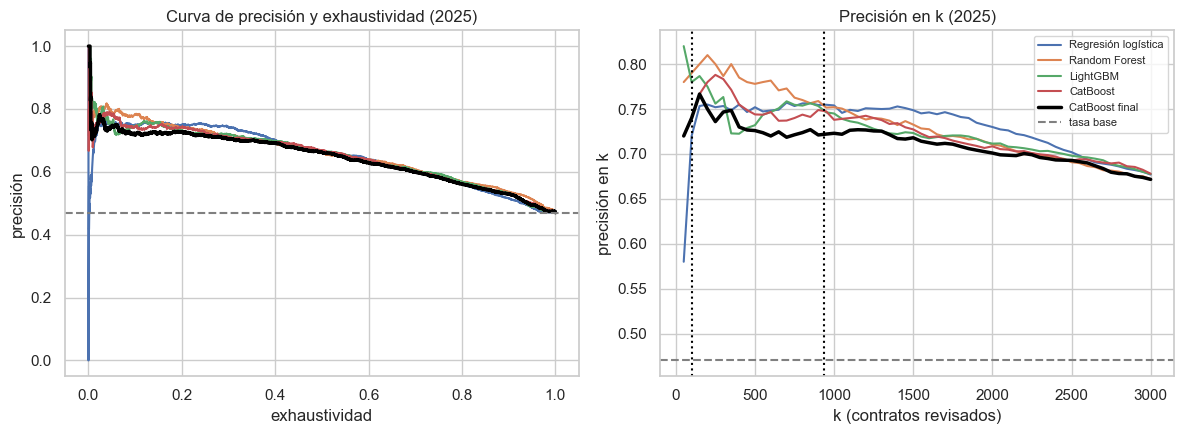


CatBoost final, alerta en el 10 % de mayor riesgo:
col_0        alerta  sin alerta   All
y                                    
con adición     679        3723  4402
sin adición     258        4703  4961
All             937        8426  9363


In [8]:
prueba = datos[datos["anio"] == PRUEBA]
finales, probs = {}, {}
for m in MODELOS:
    pipe_m, finales[NOMBRES[m]] = entrenar(
        m, params=mejores[m], evalua=PRUEBA, datos=datos)
    probs[NOMBRES[m]] = pipe_m.predict_proba(prueba[VARIABLES])[:, 1]
etiqueta_final = f"{NOMBRES[GANADOR['modelo']]} final"
final, finales[etiqueta_final] = entrenar(
    GANADOR["modelo"], evalua=PRUEBA, datos=datos, **FINAL)
p_final = final.predict_proba(prueba[VARIABLES])[:, 1]
probs[etiqueta_final] = p_final
print(pd.DataFrame(finales).T[PRINCIPALES + ["tasa_base"]].to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
k = np.arange(50, 3001, 50)
for nombre, p in probs.items():
    estilo = {"lw": 2.5, "color": "black"} if nombre == etiqueta_final else {}
    precision, recall, _ = precision_recall_curve(prueba["y"], p)
    ax[0].plot(recall, precision, label=nombre, **estilo)
    orden = prueba["y"].to_numpy()[np.argsort(-p, kind="stable")]
    ax[1].plot(k, [orden[:i].mean() for i in k], label=nombre, **estilo)
for eje in ax:
    eje.axhline(prueba["y"].mean(), ls="--", color="gray",
                label="tasa base")
ax[0].set(xlabel="exhaustividad", ylabel="precisión",
          title="Curva de precisión y exhaustividad (2025)")
ax[1].axvline(100, ls=":", color="black")
ax[1].axvline(round(0.1 * len(prueba)), ls=":", color="black")
ax[1].set(xlabel="k (contratos revisados)", ylabel="precisión en k",
          title="Precisión en k (2025)")
ax[1].legend(fontsize=8)
guardar_figura("14_prueba_2025")

alerta = p_final >= np.quantile(p_final, 0.9)
print(f"\n{etiqueta_final}, alerta en el 10 % de mayor riesgo:")
print(pd.crosstab(prueba["y"].map({0: "sin adición", 1: "con adición"}),
                  pd.Series(alerta, index=prueba.index).map(
                      {False: "sin alerta", True: "alerta"}),
                  margins=True).to_string())

**Hallazgos.**

1. En 2025 los cinco modelos quedan entre 0,645 y 0,659 de PR-AUC, frente a
   una tasa base de 0,470: la prueba confirma que su desempeño es cercano.
2. El modelo final obtiene 0,645 de PR-AUC, 0,692 de AUC-ROC y 0,74 de
   precisión en 100. Random Forest obtiene el mayor PR-AUC (0,659); la
   diferencia (0,014) no cambia la selección, que se hizo sin mirar 2025.
3. La precisión en k depende de la capacidad de revisión: Random Forest es el
   más preciso entre unos 150 y 800 contratos y la logística a partir de unos
   1.000. El modelo final se mantiene entre 0,70 y 0,77 hasta 2.000
   contratos.
4. Con la alerta en el 10 % de mayor riesgo (937 contratos), 679 tienen
   adición: precisión de 0,725, 1,54 veces la tasa base, con exhaustividad de
   0,154.
5. El AUC-ROC de prueba (0,692) es similar al de validación (0,707); el
   PR-AUC sube en 2025 porque la tasa base es mayor.

## 9. Interpretabilidad

1. Importancia por permutación del modelo final en 2025.
2. Valores SHAP agrupados por variable original para 1.000 contratos de 2025,
   con 300 contratos de entrenamiento como referencia. Es la misma función
   que alimenta el panel I del tablero (`explicar`).
3. Ejemplo local: los cinco factores del contrato con mayor riesgo de la
   muestra.

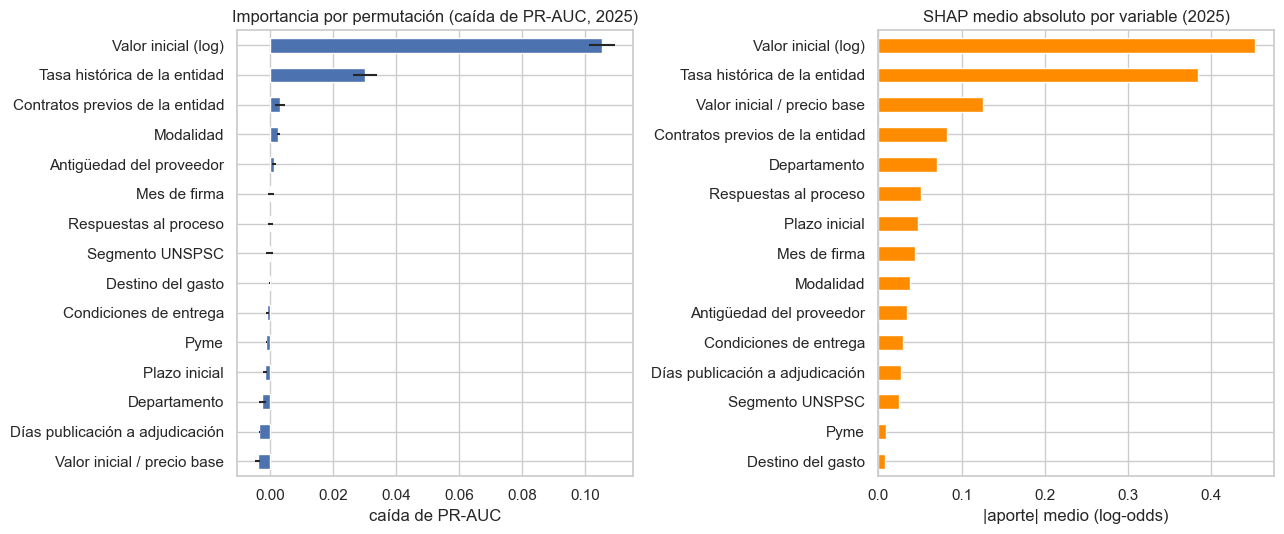

                                 media  desviación
Valor inicial (log)              0.105       0.004
Tasa histórica de la entidad     0.030       0.004
Contratos previos de la entidad  0.003       0.002
Modalidad                        0.003       0.001
Antigüedad del proveedor         0.001       0.001
Mes de firma                     0.000       0.001
Respuestas al proceso            0.000       0.001
Segmento UNSPSC                 -0.000       0.001
Destino del gasto               -0.000       0.000
Condiciones de entrega          -0.001       0.001
Pyme                            -0.001       0.000
Plazo inicial                   -0.002       0.001
Departamento                    -0.002       0.001
Días publicación a adjudicación -0.003       0.000
Valor inicial / precio base     -0.004       0.001

Contrato CO1.PCCNTR.8645608: probabilidad 0.88, adición real = 1
                                    valor  aporte (log-odds)
Contratos previos de la entidad 2,704.000              1.

In [9]:
usadas = [v for v in VARIABLES if v not in GANADOR["excluir"]]
imp = permutation_importance(
    final, prueba[VARIABLES], prueba["y"], scoring="average_precision",
    n_repeats=5, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"media": imp.importances_mean,
                            "desviación": imp.importances_std},
                           index=VARIABLES).loc[usadas].sort_values("media")

entrena = datos[datos["anio"] < PRUEBA]
fondo = entrena.sample(300, random_state=SEMILLA)
muestra = prueba.sample(1000, random_state=SEMILLA)
with contextlib.redirect_stderr(io.StringIO()):  # barra de progreso
    valores = aportes(final, muestra[VARIABLES], fondo[VARIABLES])
shap_global = valores.abs().mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
importancia.rename(index=ETIQUETAS)["media"].plot.barh(
    xerr=importancia["desviación"].to_numpy(), ax=ax[0])
ax[0].set(title="Importancia por permutación (caída de PR-AUC, 2025)",
          xlabel="caída de PR-AUC")
shap_global.rename(index=ETIQUETAS).plot.barh(ax=ax[1], color="darkorange")
ax[1].set(title="SHAP medio absoluto por variable (2025)",
          xlabel="|aporte| medio (log-odds)")
guardar_figura("15_importancia")
print(importancia.sort_values("media", ascending=False)
      .rename(index=ETIQUETAS).round(4).to_string())

riesgo = final.predict_proba(muestra[VARIABLES])[:, 1]
i = int(np.argmax(riesgo))
local = valores.iloc[i]
top = local.reindex(local.abs().sort_values(ascending=False).index[:5])
print(f"\nContrato {muestra['id_contrato'].iloc[i]}: probabilidad "
      f"{riesgo[i]:.2f}, adición real = {muestra['y'].iloc[i]}")
print(pd.DataFrame({"valor": muestra[top.index].iloc[i],
                    "aporte (log-odds)": top})
      .rename(index=ETIQUETAS).to_string())

**Hallazgos.**

1. En 2025, el valor inicial (0,105) y la tasa histórica de la entidad (0,030)
   explican casi toda la caída de PR-AUC; ninguna otra variable supera 0,004.
2. Con SHAP, el orden es el mismo en las dos primeras posiciones; les siguen
   la razón valor inicial / precio base, la experiencia de la entidad y el
   departamento.
3. Varias variables tienen importancia por permutación levemente negativa en
   2025 (valor inicial / precio base, −0,004): su relación con la adición
   cambió frente a los años de entrenamiento.
4. En el ejemplo local, un contrato con probabilidad de 0,88 y adición real,
   los factores principales son la experiencia de la entidad (2.704 contratos
   previos), su tasa histórica (0,448) y el valor inicial. Es la lectura que
   muestra el panel I del tablero.

## 10. Calibración y análisis de errores

1. Se compara la probabilidad media estimada con la tasa observada y se
   grafica la curva de calibración por deciles en 2024 (modelo entrenado con
   2019 a 2023) y en 2025 (modelo final).
2. Recalibración de Platt: el modelo entrenado con 2019 a 2023 predice 2024
   y con esas predicciones fuera de muestra se ajusta
   `y ~ sigmoide(a · logit(p) + b)`. La transformación se aplica al modelo
   final en 2025 y no cambia el orden de los contratos.
3. Censura en 2025: se compara la tasa por estado del contrato. El estado es
   posterior a la firma y solo se usa como diagnóstico.
4. Se revisa la alerta del 10 % de mayor riesgo por modalidad, tipo de
   documento del proveedor y departamento: proporción de contratos en alerta y
   precisión de la alerta. Siguiendo a Reina Hidalgo (2026), se vigila que
   ningún grupo concentre alertas sin respaldo en su tasa real.

Platt: a = 1.052, b = 0.466
2024: probabilidad media 0.273 | tasa observada 0.349 | Brier 0.200 | Brier de la tasa constante 0.227
2025: probabilidad media 0.297 | tasa observada 0.470 | Brier 0.253 | Brier de la tasa constante 0.249
2025 recalibrado: probabilidad media 0.377 | tasa observada 0.470 | Brier 0.232 | Brier de la tasa constante 0.249


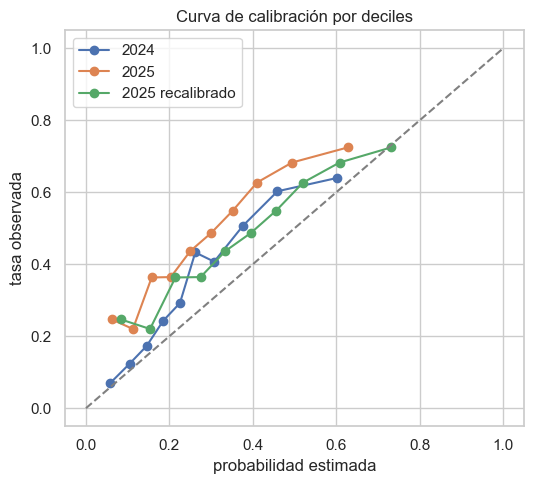


Tasa de adición por estado del contrato en 2025:
                 size  mean
estado_contrato            
Modificado       4076 0.835
terminado        2345 0.282
En ejecución     2235 0.043
Cerrado           283 0.177
Suspendido        249 0.763
Aprobado          168 0.000

Modalidad (n >= 200):
                    contratos  tasa real  % en alerta  precisión de la alerta
modalidad                                                                    
Menor cuantía            2840      0.506        0.074                   0.739
Directa                  2436      0.417        0.069                   0.473
Mínima cuantía           1799      0.313        0.020                   0.500
Licitación pública       1168      0.759        0.375                   0.826
Régimen especial         1120      0.446        0.076                   0.753

Tipo de documento del proveedor (n >= 200):
                      contratos  tasa real  % en alerta  precisión de la alerta
tipodocproveedor                

In [10]:
modelo_2024, _ = entrenar(GANADOR["modelo"], evalua=2024, datos=datos,
                          **FINAL)
valida = datos[datos["anio"] == 2024]
p_2024 = modelo_2024.predict_proba(valida[VARIABLES])[:, 1]
platt = calibrar(GANADOR["modelo"], datos=datos, **FINAL)
p_platt = recalibrar(p_final, platt)
print(f"Platt: a = {platt[0]:.3f}, b = {platt[1]:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, y_real, p in [("2024", valida["y"], p_2024),
                          ("2025", prueba["y"], p_final),
                          ("2025 recalibrado", prueba["y"], p_platt)]:
    observada, estimada = calibration_curve(y_real, p, n_bins=10,
                                            strategy="quantile")
    ax.plot(estimada, observada, marker="o", label=nombre)
    print(f"{nombre}: probabilidad media {p.mean():.3f} | tasa observada "
          f"{y_real.mean():.3f} | Brier {np.mean((p - y_real) ** 2):.3f} "
          f"| Brier de la tasa constante "
          f"{y_real.mean() * (1 - y_real.mean()):.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set(xlabel="probabilidad estimada", ylabel="tasa observada",
       title="Curva de calibración por deciles")
ax.legend()
guardar_figura("16_calibracion")

print("\nTasa de adición por estado del contrato en 2025:")
print(prueba.groupby("estado_contrato")["y"].agg(["size", "mean"])
      .sort_values("size", ascending=False).head(6).to_string())

errores = prueba.assign(alerta=alerta)


def por_segmento(variable, minimo=200):
    g = errores.groupby(variable)
    t = pd.DataFrame({
        "contratos": g.size(), "tasa real": g["y"].mean(),
        "% en alerta": g["alerta"].mean(),
        "precisión de la alerta":
            errores[errores["alerta"]].groupby(variable)["y"].mean(),
    })
    return t[t["contratos"] >= minimo].sort_values("contratos",
                                                   ascending=False)


for variable in ["modalidad", "tipodocproveedor", "departamento"]:
    print(f"\n{ETIQUETAS[variable]} (n >= 200):")
    print(por_segmento(variable).to_string())

**Hallazgos.**

1. El modelo subestima la probabilidad: estima 0,273 frente a 0,349 observado
   en 2024 y 0,297 frente a 0,470 en 2025. En 2025 su Brier (0,253) es peor
   que el de la tasa constante (0,249).
2. La recalibración de Platt ajustada con 2024 (a = 1,052; b = 0,466) sube la
   probabilidad media a 0,377 y baja el Brier a 0,232, mejor que la tasa
   constante, sin cambiar el orden. La brecha restante se debe al salto de la
   tasa en 2025, que no se podía anticipar con 2024.
3. Censura: 2.235 contratos de 2025 siguen "En ejecución" con una tasa
   registrada de 4,3 %, frente a 83,5 % en "Modificado". La etiqueta de 2025
   está incompleta y las métricas de prueba deben leerse con esa salvedad.
4. Por modalidad, la alerta se concentra en licitación pública (37,5 % de sus
   contratos, precisión de 0,826), coherente con su tasa real de 75,9 %; la
   mínima cuantía casi no recibe alertas (2,0 %).
5. Los contratistas con cédula reciben menos alertas que los que tienen NIT
   (4,4 % y 9,4 %), con precisión similar (0,673 y 0,700).
6. Cauca recibe alertas sin respaldo: 16,1 % de sus contratos en alerta con
   precisión de 0,317, igual a su tasa real. De sus 63 alertas, 34 son
   contratos directos de la Gobernación del Cauca con 2,9 % de adición; la
   entidad tuvo 68,6 % en 2019 a 2024 y 11,3 % en 2025.
7. Antioquia, Boyacá, Norte de Santander y Huila reciben pocas alertas (0,5 %
   a 4,0 %) con precisión alta: el umbral nacional deja contratos de riesgo
   sin alerta en esos departamentos.

## 11. Modelos por tipo de adición

1. La configuración final se entrena también para `y_tiempo` e `y_valor`, que
   alimentan las dos probabilidades del tablero (elemento H).
2. Se reporta la validación temporal y la prueba en 2025 frente a la tasa
   base de cada objetivo.

In [11]:
filas = {}
for obj in OBJETIVOS:
    v = validar(GANADOR["modelo"], obj, datos=datos, **FINAL)
    _, t = entrenar(GANADOR["modelo"], obj, evalua=PRUEBA, datos=datos,
                    **FINAL)
    filas[obj] = {"PR-AUC validación": v["pr_auc"].mean(),
                  "tasa base validación": v["tasa_base"].mean(),
                  "PR-AUC prueba": t["pr_auc"],
                  "tasa base prueba": t["tasa_base"],
                  "AUC-ROC prueba": t["roc_auc"],
                  "precisión en 100": t["precision_100"],
                  "precisión top 10 %": t["precision_10pct"],
                  "lift top 10 %": t["lift_10pct"]}
print(pd.DataFrame(filas).T.to_string())

          PR-AUC validación  tasa base validación  PR-AUC prueba  tasa base prueba  AUC-ROC prueba  precisión en 100  precisión top 10 %  lift top 10 %
y                     0.523                 0.328          0.645             0.470           0.692             0.740               0.725          1.543
y_tiempo              0.484                 0.253          0.615             0.425           0.710             0.710               0.698          1.642
y_valor               0.215                 0.094          0.180             0.079           0.702             0.390               0.209          2.664


**Hallazgos.**

1. Para `y_tiempo`, el PR-AUC de prueba es 0,615 frente a una tasa base de
   0,425, con lift de 1,64 en el 10 % de mayor riesgo.
2. Para `y_valor`, el PR-AUC es 0,180 frente a 0,079: la adición en valor es
   rara y difícil de anticipar, pero la lista del 10 % de mayor riesgo
   concentra 2,66 veces la tasa base.
3. Los tres modelos son independientes y sus probabilidades no siempre son
   coherentes: la de `y` puede quedar por debajo de la de `y_tiempo`. El
   tablero muestra como riesgo total el máximo de las tres
   (`docs/modelos.md`).

## 12. Modelo final

El modelo final se guarda para los tres objetivos con
`python src/modelo.py --ganador`, que entrena con 2019 a 2024, ajusta la
recalibración de Platt con 2024, imprime las métricas de prueba de las
secciones 8 y 11 y escribe `models/modelo_{objetivo}.joblib` (pipeline y
coeficientes de Platt). El tablero lo consume con `predecir`, que devuelve la
probabilidad recalibrada, y `explicar` (guía en `docs/modelos.md`).

## 13. Conclusiones

1. **Desempeño.** Los cuatro modelos tienen un desempeño cercano: PR-AUC medio
   de 0,514 a 0,528 en validación y de 0,645 a 0,659 en prueba, frente a
   tasas base de 0,328 y 0,470. El límite lo pone la información disponible
   al firmar más que el algoritmo.
2. **Selección.** Se selecciona CatBoost (profundidad 6, tasa de aprendizaje
   0,03) con 15 variables, por el mayor PR-AUC medio en validación. La
   selección se confirma con las corridas registradas en MLflow.
3. **Utilidad para priorizar.** En el 10 % de mayor riesgo de 2025 el modelo
   acierta en el 72,5 % de los contratos, frente a 47,0 % de la tasa base; en
   la adición en valor la lista concentra 2,7 veces la tasa base.
4. **Variables.** El valor inicial y la historia de la entidad (tasa de
   adición y experiencia) dominan la predicción, en línea con el EDA y con
   Rodríguez Arévalo (2021) y Salazar Mejía (2024). Las métricas son menores
   que las reportadas en esos trabajos (precisión de 0,92 y MAP@100 de 1,00)
   porque aquí se excluyen las variables que incorporan las adiciones y la
   partición es temporal.
5. **Calibración.** La deriva en el registro de las adiciones afecta la
   probabilidad: la recalibración de Platt corrige parte de la subestimación
   (Brier de 0,253 a 0,232), pero la probabilidad sigue por debajo de la tasa
   de 2025. El tablero usa el percentil y el nivel de alerta como lectura
   principal.
6. **Limitaciones.** Etiqueta incompleta en 2025 (2.235 contratos en
   ejecución con 4,3 % de adición registrada), desempeño desigual entre
   departamentos (Cauca) y modelos independientes por tipo de adición sin
   coherencia garantizada entre sus probabilidades.
7. **Uso responsable.** El modelo prioriza la vigilancia y no decide: cada
   alerta lleva su explicación y requiere revisión humana (Reina Hidalgo,
   2026).
8. **Próximos pasos.** Registrar los experimentos en MLflow y confirmar la
   selección; evaluar CatBoost con categóricas nativas y orden temporal, que
   superó al preprocesamiento común en la verificación de la auditoría 06;
   reentrenar con 2025 cuando su etiqueta madure; y guardar en caché las
   explicaciones SHAP en la API de la Entrega 3.